In [2]:
import pandas as pd  # loading and manupulating data
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier  # Machine Learning
from sklearn.model_selection import train_test_split  
import numpy as np

In [3]:
# Load the data
X = pd.read_csv(r"D:\Data Science_bat\Machine Learning\linear_regression_project\raw_data\indian_engineering_student_placement.csv")
y = pd.read_csv(r"D:\Data Science_bat\Machine Learning\linear_regression_project\raw_data\placement_targets.csv")

In [4]:
X = X[['study_hours_per_day']]
y = y['placement_status']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X,y)

<Axes: xlabel='placement_status'>

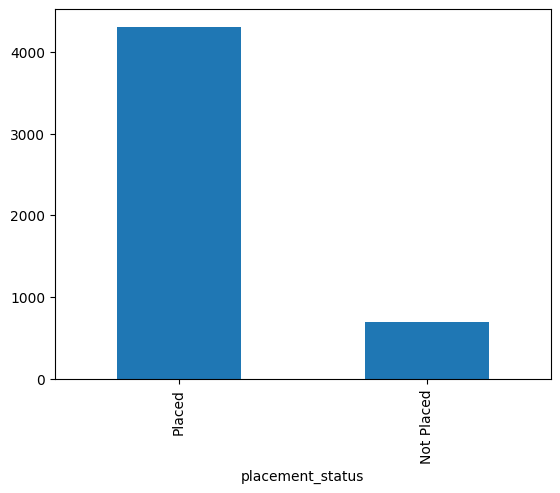

In [6]:
y.value_counts().plot(kind='bar')

In [7]:
y_test = y_test.map(lambda x: 1 if x == "Placed" else 0)


class_weight='balanced'

In [23]:
DTree_model = DecisionTreeClassifier(class_weight='balanced')
DTree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [24]:
pred = DTree_model.predict(X_test)

In [25]:
pred = (pred == "Placed").astype(int)

In [26]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score,f1_score

precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)
f1 = f1_score(y_test, pred)
conf_mat = confusion_matrix(y_test, pred)


In [27]:
from sklearn.metrics import accuracy_score


accuracy_score(y_test, pred)

0.5208

In [28]:
DTree_model.score(X_train,y_train)

0.5605333333333333

In [30]:
print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1 Score : {f1}")



precision : 0.8819875776397516
recall : 0.5206232813932172
f1 Score : 0.6547550432276658


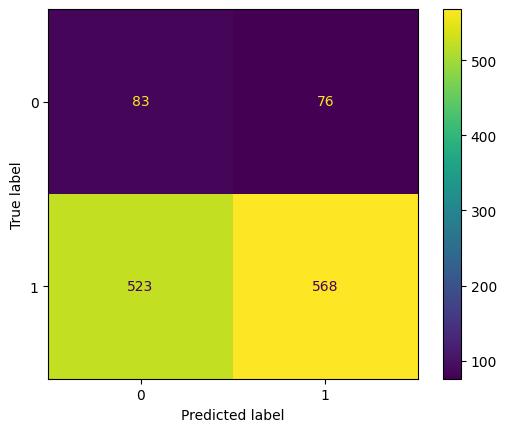

In [31]:

from sklearn.metrics import ConfusionMatrixDisplay

confus_matrx = ConfusionMatrixDisplay(conf_mat)
confus_matrx.plot()

In [32]:

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt


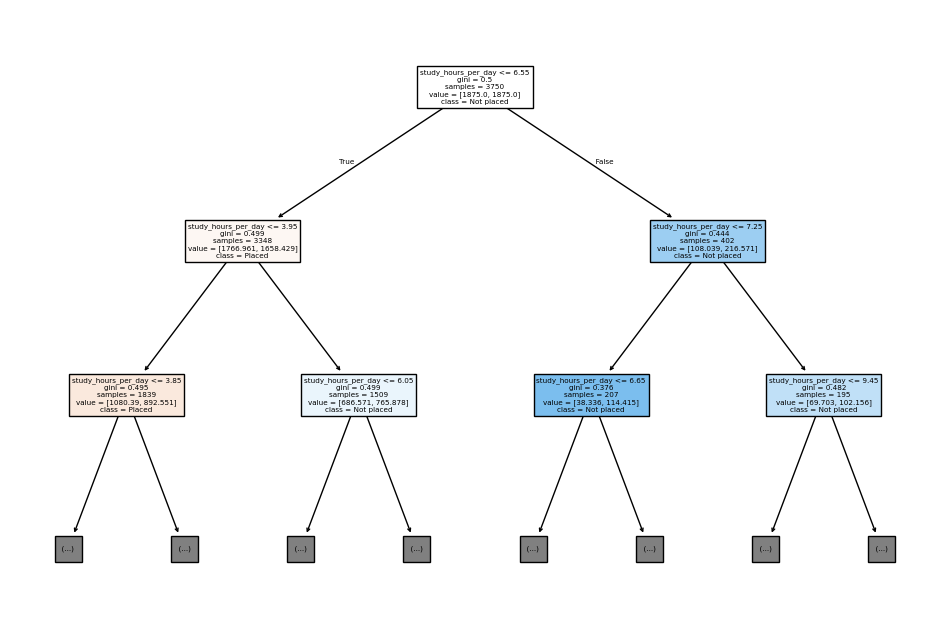

In [33]:

plt.figure(figsize=(12,8))
plot_tree(DTree_model,
          max_depth=2,
          feature_names=DTree_model.feature_names_in_,
          class_names=['Placed','Not placed'],
          filled=True)
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier


rf_classifier = RandomForestClassifier(criterion='entropy' , class_weight='balanced', max_features='log2'
                                       )
rf_classifier.fit(X_train, y_train)


,n_estimators,100
,criterion,'entropy'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'log2'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [53]:
pred = rf_classifier.predict(X_test)

In [54]:
pred = (pred == "Placed").astype(int)

In [55]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score,f1_score

precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)
f1 = f1_score(y_test, pred)
conf_mat = confusion_matrix(y_test, pred)

print(f"precision : {precision}")
print(f"recall : {recall}")
print(f"f1 Score : {f1}")


precision : 0.8743781094527363
recall : 0.6443629697525206
f1 Score : 0.7419525065963061


In [56]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, pred)

0.6088

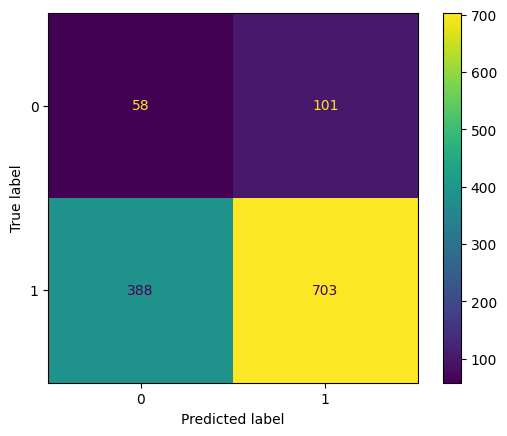

In [57]:
from sklearn.metrics import ConfusionMatrixDisplay

confus_matrx = ConfusionMatrixDisplay(conf_mat)
confus_matrx.plot()